In [86]:
import os
import os.path as path

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PMC_NAME = "IntSch1TokenStall"
DATA_DIR = "../odata/"

BUSY_SIBLING_COLOR = 'blue'
IDLE_SIBLING_COLOR = 'orange'
DELTA_TIME_STR = r'$\Delta_t$ (cycles)'

def get_latest_csv_file(directory):
    csv_files = [f for f in os.listdir(directory) if f.endswith('.csv')]
    if not csv_files:
        raise FileNotFoundError("No CSV files found in the directory.")
    latest_file = max(csv_files, key=lambda f: path.getmtime(path.join(directory, f)))
    return path.join(directory, latest_file)

In [87]:
latest_csv = get_latest_csv_file(DATA_DIR)
print(f"Latest CSV file: {latest_csv}")
df = pd.read_csv(latest_csv)

Latest CSV file: ../odata/bench_20261105_142809_cpu0.csv


# Scheduler queue Contention

This section illustrates the significant increasement in latency of `mul` instructions
when a scheduler queue is FULL.

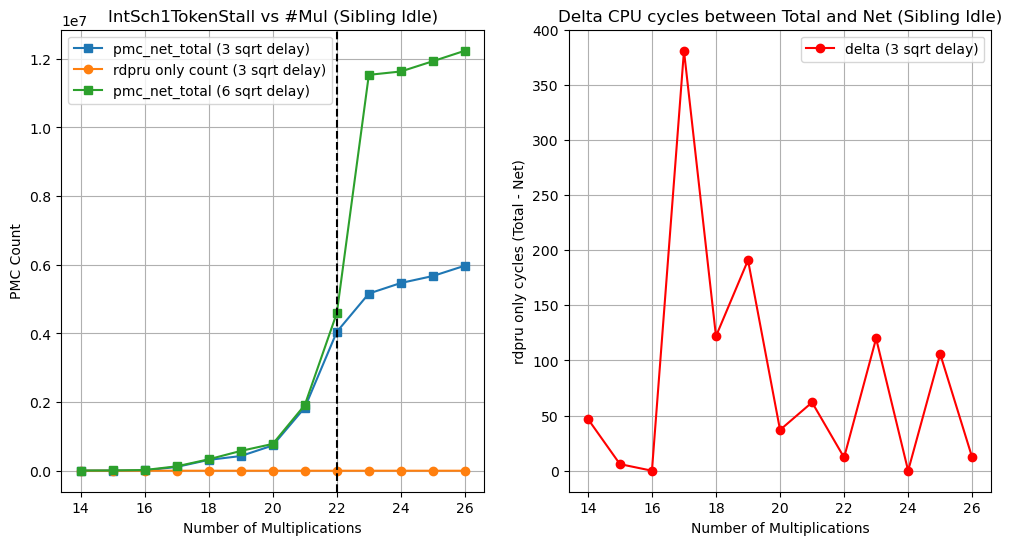

In [88]:
sibling_idle_df = df[df['sibling_state'] == 'idle']
# get vaules of 'pmc_net_per_region' and 'fill_entry' columns for sibling_idle_df

three_sqrt_delay_df = sibling_idle_df[sibling_idle_df['sqrt_delay'] == 3]
six_sqrt_delay_df = sibling_idle_df[sibling_idle_df['sqrt_delay'] == 6]


NORM_FACTOR = 1e5
x_vals = three_sqrt_delay_df[['fill_entry']].to_numpy()  # fill_entry
three_delay_net_count = three_sqrt_delay_df[['pmc_net_total']].to_numpy()   # pmc_net
three_delay_total_count = three_sqrt_delay_df[['pmc_body_total']].to_numpy()  # pmc_body_total
# y2_vals = three_sqrt_delay_df[['pmc_body_total']].to_numpy()  # pmc_body_total
three_delay_empty_count = three_sqrt_delay_df[['pmc_empty_total']].to_numpy()  # rdpru only count
six_delay_net_count = six_sqrt_delay_df[['pmc_net_total']].to_numpy()   # pmc_net

# Plotting the data
# side-by-side subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
ax1.plot(x_vals, three_delay_net_count, marker='s', label='pmc_net_total (3 sqrt delay)')
ax1.plot(x_vals, three_delay_empty_count, marker='o', label='rdpru only count (3 sqrt delay)')
ax1.plot(x_vals, six_delay_net_count, marker='s', label='pmc_net_total (6 sqrt delay)')
ax1.axvline(x=22, color='black', linestyle='--')
ax1.set_xlabel('Number of Multiplications')
ax1.set_ylabel('PMC Count')
ax1.set_title(f'{PMC_NAME} vs #Mul (Sibling Idle)')
ax1.legend()
ax1.grid(True)

ax2.plot(x_vals, three_delay_total_count - three_delay_net_count, marker='o', color='red', label='delta (3 sqrt delay)')
ax2.set_xlabel('Number of Multiplications')
ax2.set_ylabel('rdpru only cycles (Total - Net)')
ax2.set_title('Delta CPU cycles between Total and Net (Sibling Idle)')
ax2.legend()
ax2.grid(True)

plt.show()

`Total = rdpru overhead + Net (set of tested instructions)`

`intSch1TokenStall` is a counter which increase 1 cycle when a uop COULD NOT be dispatched because the scheduler queue has NO free entries. It is different from the APERF counter read by `rdpru`.

On Zen 3, we have 24 ALU1 entries for multiplications ONLY, that means mul instructions from thread MUST compete to each other for a single available slot of ALU1.

Addition and Substraction could be done in ALL four ALUs (ALU0-ALU3)

## Sibling Idle VS Sibling Busy

### AMD Zen 3

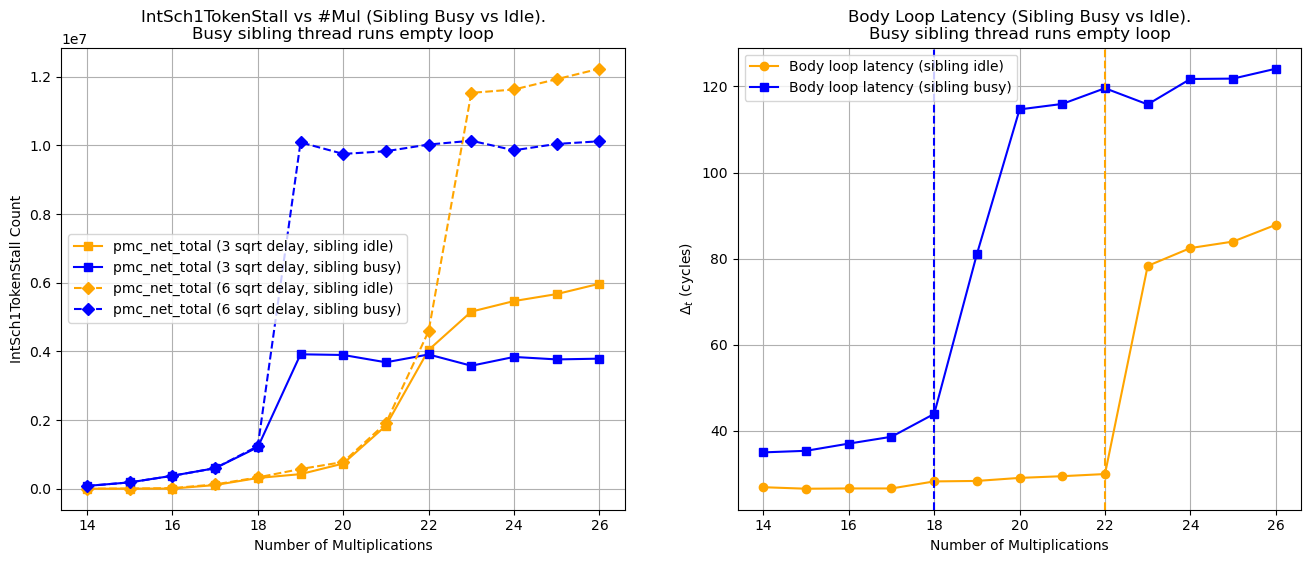

In [89]:
sibling_busy_df = df[df['sibling_state'] == 'busy']

# Filter the DataFrame for 3-sqrt and 6-sqrt delay cases
three_sqrt_delay_busy_df = sibling_busy_df[sibling_busy_df['sqrt_delay'] == 3]
six_sqrt_delay_busy_df = sibling_busy_df[sibling_busy_df['sqrt_delay'] == 6]

# x-axis: number of multiplications
x_vals_busy = three_sqrt_delay_busy_df[['fill_entry']].values  # fill_entry

# 3-sqrt delay cases
three_delay_net_count_busy = three_sqrt_delay_busy_df[['pmc_net_total']].values   # pmc_net
three_delay_total_count_busy = three_sqrt_delay_busy_df[['pmc_body_total']].values  # pmc_body_total
three_delay_empty_count_busy = three_sqrt_delay_busy_df[['pmc_empty_total']].values  # rdpru only count

# 6-sqrt delay cases
six_delay_net_count_busy = six_sqrt_delay_busy_df[['pmc_net_total']].values   # pmc_net

# Get data of time latency of an empty loop (no multiplication) for sibling busy and idle
# (1-D arrays: errorbar() rejects the (n, 1) shape produced by df[['col']].values)
body_loop_idle_median = three_sqrt_delay_df['body_median'].to_numpy()
body_loop_idle_stddev = three_sqrt_delay_df['body_stddev'].to_numpy()
body_loop_idle_mean = three_sqrt_delay_df['body_mean'].to_numpy()

# Busy sibling
body_loop_busy_median = three_sqrt_delay_busy_df['body_median'].to_numpy()
body_loop_busy_stddev = three_sqrt_delay_busy_df['body_stddev'].to_numpy()
body_loop_busy_mean = three_sqrt_delay_busy_df['body_mean'].to_numpy()

assert len(body_loop_idle_median) == len(body_loop_busy_median), "Mismatch in lengths of body loop latency data"
assert np.shape(body_loop_idle_median) == np.shape(body_loop_idle_stddev)
assert len(x_vals) == len(body_loop_idle_median), "Mismatch in lengths of x_vals and body loop latency data"

# Ploting the data between sibling busy and idle
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

ax1.plot(x_vals, three_delay_net_count, linestyle='-', marker='s', color=IDLE_SIBLING_COLOR, label='pmc_net_total (3 sqrt delay, sibling idle)')
ax1.plot(x_vals, three_delay_net_count_busy, linestyle='-', marker='s', color=BUSY_SIBLING_COLOR, label='pmc_net_total (3 sqrt delay, sibling busy)')
ax1.plot(x_vals, six_delay_net_count, linestyle='--', marker='D', color=IDLE_SIBLING_COLOR, label='pmc_net_total (6 sqrt delay, sibling idle)')
ax1.plot(x_vals, six_delay_net_count_busy, linestyle='--', marker='D', color=BUSY_SIBLING_COLOR, label='pmc_net_total (6 sqrt delay, sibling busy)')

ax1.set_xlabel('Number of Multiplications')
ax1.set_ylabel(f'{PMC_NAME} Count')
ax1.set_title(f'{PMC_NAME} vs #Mul (Sibling Busy vs Idle).\nBusy sibling thread runs empty loop')
ax1.legend()
ax1.grid(True)

# ax2.errorbar(x_vals.ravel(), body_loop_idle_median, yerr=body_loop_idle_stddev, fmt='o', label='Body loop latency (sibling idle)', capsize=5)
# ax2.errorbar(x_vals.ravel(), body_loop_busy_median, yerr=body_loop_busy_stddev, fmt='s', label='Body loop latency (sibling busy)', capsize=5)
ax2.plot(x_vals, body_loop_idle_mean, marker='o', color=IDLE_SIBLING_COLOR, label='Body loop latency (sibling idle)')
ax2.plot(x_vals, body_loop_busy_mean, marker='s', color=BUSY_SIBLING_COLOR, label='Body loop latency (sibling busy)')
ax2.axvline(x=22, color=IDLE_SIBLING_COLOR, linestyle='--')
ax2.axvline(x=18, color=BUSY_SIBLING_COLOR, linestyle='--')
ax2.set_xlabel('Number of Multiplications')
ax2.set_ylabel(DELTA_TIME_STR)
ax2.set_title('Body Loop Latency (Sibling Busy vs Idle).\nBusy sibling thread runs empty loop')
ax2.legend()
ax2.grid(True)

plt.show()

## Classifiable latency signals through long time series

In [90]:
latest_timeseries_csv = get_latest_csv_file(path.join(DATA_DIR, "ts"))
print(f"Latest time series CSV file: {latest_timeseries_csv}")
ts_df = pd.read_csv(latest_timeseries_csv)


# Get block size
BL_SIZE = int(latest_timeseries_csv.split('_')[-1].split('.')[0].split('block')[-1])
print(f"Block size: {BL_SIZE}")

Latest time series CSV file: ../odata/ts/bench_20261105_163725_cpu0_timeseries_block15.csv
Block size: 15


Dropped 0 negative-latency samples out of 437365
         samples    mean  median     p5    p95     std
sibling                                               
imul      235311  117.12   119.0  107.0  123.0  151.92
nop       202054   40.31    38.0   38.0   38.0  347.72


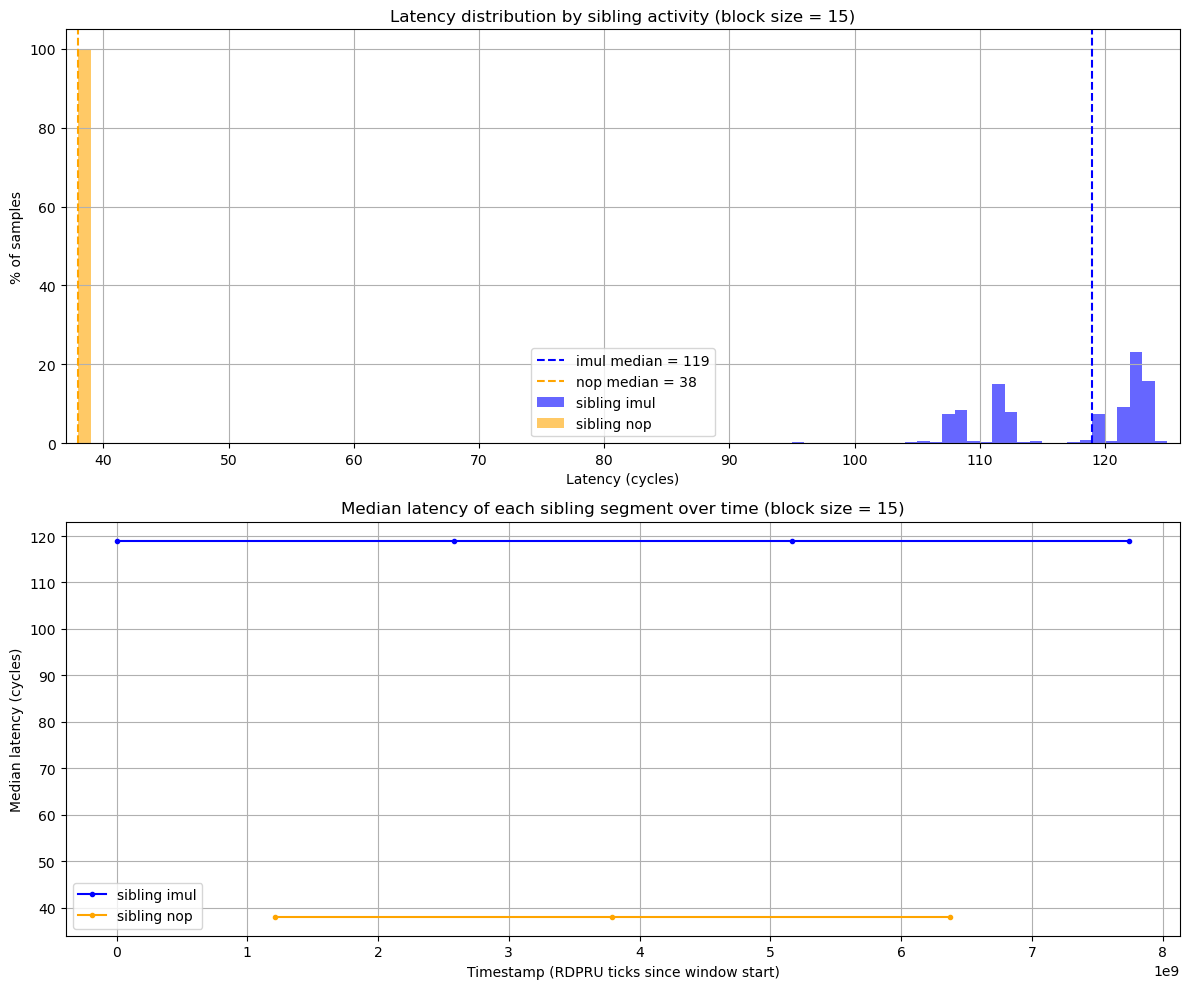

In [91]:
# The unfenced RDPRU reads can complete out of order, giving a NEGATIVE elapsed
# time. The C code writes it as an unsigned 64-bit number (2^64 - x), which
# pandas reads as uint64. Reinterpret the column as signed, then drop those samples.
raw_latency = ts_df['latency'].to_numpy().astype(np.uint64).view(np.int64)
valid = raw_latency >= 0
print(f"Dropped {np.count_nonzero(~valid)} negative-latency samples out of {len(valid)}")

clean_df = ts_df.loc[valid].copy()
clean_df['latency'] = raw_latency[valid]
# only samples taken while the sibling ran a segment (seg_id 0 = before it started)
seg_df = clean_df[clean_df['sibling'].isin(['imul', 'nop'])]

SIBLING_COLORS = {'imul': 'blue', 'nop': 'orange'}

# ---- summary: one row per sibling activity ---------------------------------
summary = seg_df.groupby('sibling')['latency'].agg(
    samples='count', mean='mean', median='median',
    p5=lambda s: np.percentile(s, 5), p95=lambda s: np.percentile(s, 95),
    std='std').round(2)
print(summary)

# ---- figure: (1) latency distributions, (2) median latency per segment -------
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# (1) overlaid histograms, 1-cycle bins, as % of that activity's samples
# (the two activities have different sample counts, so raw counts would mislead).
# The range is clipped at the 0.1th / 99.9th percentile to drop rare outliers.
LAT_MIN = int(np.percentile(seg_df['latency'], 0.1)) - 1
LAT_MAX = int(np.percentile(seg_df['latency'], 99.9)) + 2
bins = np.arange(LAT_MIN, LAT_MAX + 1)
for who, color in SIBLING_COLORS.items():
    lat = seg_df.loc[seg_df['sibling'] == who, 'latency'].to_numpy()
    counts, _ = np.histogram(lat, bins=bins)
    ax1.bar(bins[:-1], counts / counts.sum() * 100, width=1.0, align='edge',
            color=color, alpha=0.6, label=f'sibling {who}')
    ax1.axvline(np.median(lat), color=color, linestyle='--',
                label=f'{who} median = {np.median(lat):.0f}')
ax1.set_xlim(LAT_MIN, LAT_MAX)
ax1.set_xlabel('Latency (cycles)')
ax1.set_ylabel('% of samples')
ax1.set_title(f'Latency distribution by sibling activity (block size = {BL_SIZE})')
ax1.legend()
ax1.grid(True)

# (2) one point per segment: median latency, at the segment's start time
# (.to_numpy(): this matplotlib cannot plot pandas Series directly)
seg_stats = (seg_df.groupby(['seg_id', 'sibling'])
             .agg(t_start=('timestamp', 'min'), median=('latency', 'median'))
             .reset_index())
for who, color in SIBLING_COLORS.items():
    s = seg_stats[seg_stats['sibling'] == who]
    ax2.plot(s['t_start'].to_numpy(), s['median'].to_numpy(), marker='o',
             markersize=3, linestyle='-', color=color, label=f'sibling {who}')
ax2.set_xlabel('Timestamp (RDPRU ticks since window start)')
ax2.set_ylabel('Median latency (cycles)')
ax2.set_title(f'Median latency of each sibling segment over time (block size = {BL_SIZE})')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [92]:
print(seg_df.groupby('sibling').latency.describe())

            count        mean         std   min    25%    50%    75%      max
sibling                                                                      
imul     235311.0  117.118630  151.924073  28.0  111.0  119.0  122.0  52430.0
nop      202054.0   40.305567  347.718460  25.0   38.0   38.0   38.0  68180.0


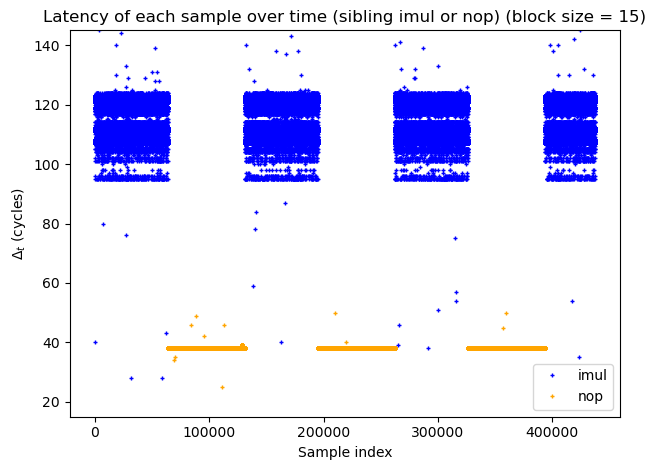

In [ ]:
filtered_df = seg_df[seg_df['latency'] > 0]

plt.figure()

plt.ylim([15,145])
for who, color in SIBLING_COLORS.items():
    s = filtered_df[filtered_df['sibling'] == who]
    # x = the sample's row number in the CSV (s.index keeps the original labels,
    # so it stays correct after the latency filter dropped some rows)
    plt.plot(s.index.to_numpy(), s['latency'].to_numpy(), marker='+',
             markersize=6, linestyle='None', color=color, label=f'{who}')
plt.legend()

plt.xlabel('Sample index')
plt.ylabel(DELTA_TIME_STR)
plt.title(f'Latency of each sample over time (sibling imul or nop) (block size = {BL_SIZE})')

plt.tight_layout()
plt.show()

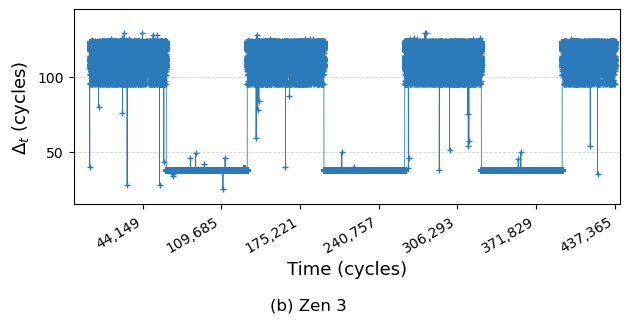

In [ ]:
# Paper-style figure (imgs/fig6b_crop.png): one series, '+' markers, y = latency
# of every sample (cycles), x = sample index with a tick every 2^16 samples,
# counted back from the last sample (44,149 ... 437,365 for 437,365 samples).
PLOT_CAPTION = '(b) Zen 3'
LAT_CLIP = 130          # as in the reference: drop the rare interrupt spikes
TICK_STEP = 1 << 16     # 65,536 samples

plot_df = seg_df[seg_df['latency'] < LAT_CLIP]
n_samples = len(ts_df)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(plot_df.index.to_numpy(), plot_df['latency'].to_numpy(),
        marker='+', markersize=5, linewidth=0.6, color='#2b7bba')

ax.set_xlim(-0.03 * n_samples, 1.01 * n_samples)
ax.set_ylim(15, 145)
ax.set_yticks([50, 100])
ax.yaxis.grid(True, linestyle='--', linewidth=0.6, color='lightgray')
ax.set_axisbelow(True)

ticks = np.arange(n_samples % TICK_STEP, n_samples + 1, TICK_STEP)
ax.set_xticks(ticks)
ax.set_xticklabels([f'{t:,}' for t in ticks], rotation=30, ha='right')

ax.set_ylabel(DELTA_TIME_STR, fontsize=13)
ax.set_xlabel('Time (cycles)', fontsize=13)
fig.text(0.5, 0.01, PLOT_CAPTION, ha='center', fontsize=12)
fig.subplots_adjust(left=0.14, right=0.98, top=0.95, bottom=0.34)

plt.show()
